# Customer Loyalty Prediction: Modeling the Relationship Between Spending Patterns and Customer Loyalty

In [23]:
# Importing packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.formula.api import logit
from scipy.stats import chi2

from pathlib import Path
import pickle
import os

### Question 4

4. Are high spenders actually more loyal?
Churn falls as spend rises, from about 83% in the lowest spend quintile to about 66% in the highest. You could explore whether this holds within each plan, or whether spend is just a proxy for plan tier. That tells you if upselling reduces churn or just reflects who was already loyal.

In [42]:
# Set directories
cdir = Path.cwd()
root = cdir.parent
ds_dir = f'{root}/data/'
rs_dir = f'{cdir}/results/'
os.makedirs(rs_dir,exist_ok=True)

def save_result(res_name,object,directory=rs_dir):
    with open(directory+res_name+'.pkl', 'wb') as save:
        pickle.dump(object, save)
    return object

def viz_bar(x,y,data,ax,patch:bool,hue:str=None):
    p = sns.barplot(
        x=x, y=y, data=data, hue=hue, ax=ax, errorbar=None
    )
    if patch:
        for p in ax.patches:
            if p.get_height() > 0:
                height=p.get_height()
                ax.annotate(
                    f'{height:.2f}',
                    xy=(p.get_x()+p.get_width()/2,height),
                    xytext=(0,3),
                    textcoords='offset points',
                    ha='center', va='bottom'
                )

def viz_reg(x,y,data,logistic:bool=False):
    sns.regplot(
        x=x, y=y, data=data, logistic=logistic
    )

def get_quantiles(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3-q1
    lower_bound = q1 - (iqr*1.5)
    upper_bound = q1 - (iqr*1.5)
    return q1,q3,iqr,lower_bound,upper_bound

def model_logit(formula,data,model_name:str=None):
    model = logit(formula,data).fit(disp=0)
    summary = model.summary().tables[1]

    if model_name:
        save_result(model_name,summary)
    
    return model, summary

def get_lhood_ratio(title:str,f_model,c_model,sig=0.05):
    lhood = 2 * (f_model.llf - c_model.llf)
    if (f_model.df_model-c_model.df_model) == 0:
        ddof = 1
    else:
        ddof = f_model.df_model - c_model.df_model
    p_val = chi2.sf(lhood,ddof)

    frame = pd.DataFrame({
        'Model':title,'LR':lhood, 'Degrees of Freedom':ddof, 'P-value':p_val, 'Reject':p_val<sig,
        'OR per $10':(np.exp(f_model.params['monthly_spend']*10)-1)*100
    },index=[0]).reset_index(drop=True)

    return frame

In [25]:
dataset = '../data/customer_churn_clean.csv'
df = pd.read_csv(ds_dir+'customer_churn_clean.csv', index_col=0)
df.head()

,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,10001,male,east,basic,paypal,27.0,27,1.0,61.08,0
1,10002,unknown,west,pro,paypal,55.0,146,2.0,73.09,0
2,10003,female,west,pro,e-wallet,NaN,147,2.0,116.30,1
3,10004,female,south,basic,credit_card,NaN,34,1.0,0.58,1
4,10005,male,north,basic,crypto,30.0,146,3.0,46.35,1


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             10300 non-null  int64  
 1   gender                  10300 non-null  str    
 2   region                  10300 non-null  str    
 3   subscription_plan       10300 non-null  str    
 4   payment_method          9575 non-null   str    
 5   age                     8718 non-null   float64
 6   days_since_last_login   10300 non-null  int64  
 7   customer_service_calls  10248 non-null  float64
 8   monthly_spend           9715 non-null   float64
 9   churn                   10300 non-null  int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 804.8 KB


#### Analysis Variables
* Subscription Plan
    - customer's current service tier
* Monthly Spend
    - average monthly revenue
* Churn
    - Taget variable. 1 = Churned, 0 = Retained

**_Objectives_**
* Identify the relationship between revenue and churn
* Diagnose if revenue is a proxy for subscription plan
* Churn ~ Revenue analysis given that revenue is the strongest driver of attrition

In [27]:
# Subsetting analysis variables
subset = df[['subscription_plan','monthly_spend','churn']].dropna().copy()
subset.head()

,subscription_plan,monthly_spend,churn
0,basic,61.08,0
1,pro,73.09,0
2,pro,116.30,1
3,basic,0.58,1
4,basic,46.35,1


In [28]:
# Isolating zero spenders to the analysis
# Zero spenders doesn't produce significant revenue for the analysis
non_zero = subset[subset.monthly_spend>0].copy()
non_zero.head()

,subscription_plan,monthly_spend,churn
0,basic,61.08,0
1,pro,73.09,0
2,pro,116.30,1
3,basic,0.58,1
4,basic,46.35,1


In [29]:
non_zero[['subscription_plan','churn']].value_counts(normalize=True)*100

subscription_plan  churn
basic              1        33.689964
pro                1        26.084428
plus               1        15.315734
basic              0         8.733574
pro                0         8.617281
plus               0         7.559018
Name: proportion, dtype: float64

In [30]:
# Creating a table of revenue per subscription plan
# Grouped by churn status
# Set group
group = ['subscription_plan','churn']
table = non_zero.groupby(group).agg(
        total_subs=('subscription_plan','count'),
        avg_revenue=('monthly_spend','mean'),
        total_revenue=('monthly_spend','sum')
    ).sort_values(by='churn').reset_index()

revenue_table = save_result('revenue_table',table)
revenue_table

,subscription_plan,churn,total_subs,avg_revenue,total_revenue
0,basic,0,751,49.796085,37396.86
1,plus,0,650,163.682385,106393.55
2,pro,0,741,94.345547,69910.05
3,basic,1,2897,44.239009,128160.41
4,plus,1,1317,157.367160,207252.55
5,pro,1,2243,83.858275,188094.11


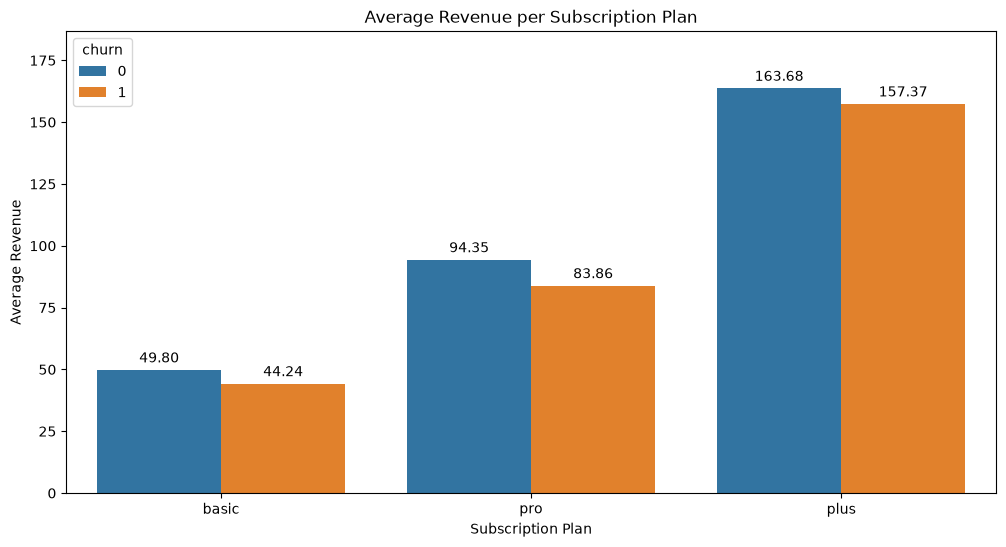

In [31]:
# Visualizing average revenue per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
x='subscription_plan'
y='monthly_spend'
data=non_zero
hue='churn'
ax=ax
viz_bar(x,y,data,ax,True,hue)
plt.ylabel('Average Revenue')
plt.xlabel('Subscription Plan')
plt.title('Average Revenue per Subscription Plan')
plt.ylim(0, non_zero.monthly_spend.max()*0.60)
plt.show()


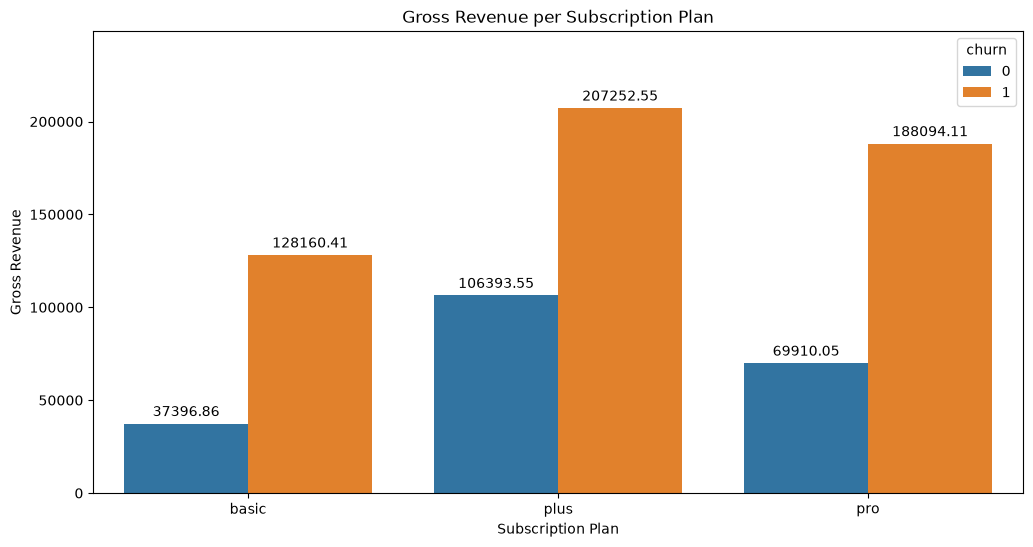

In [32]:
# Visualizing total revenue per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
x = 'subscription_plan'
y = 'total_revenue'
data = revenue_table
hue = 'churn'
viz_bar(x,y,data,ax,True,hue)
plt.ylabel('Gross Revenue')
plt.xlabel('Subscription Plan')
plt.title('Gross Revenue per Subscription Plan')
plt.ylim(0, revenue_table.total_revenue.max()*1.2)
plt.show()


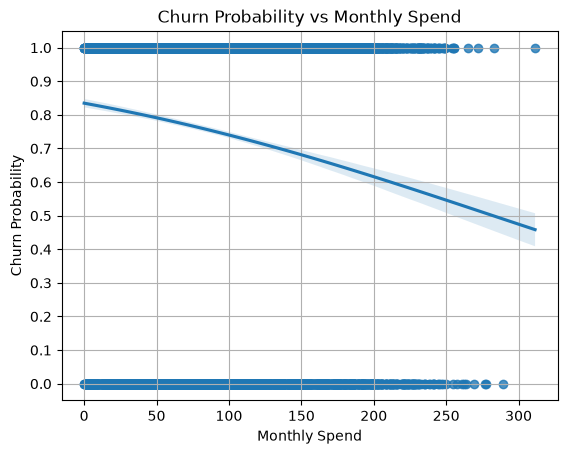

In [33]:
# Visualizing the trend line of revenue and churn probability
x='monthly_spend'
y='churn'
data=non_zero
logistic=True
viz_reg(x,y,data,logistic)
plt.ylabel('Churn Probability')
plt.xlabel('Monthly Spend')
plt.title('Churn Probability vs Monthly Spend')
plt.yticks(np.arange(0,1.1,0.1))
plt.grid()
plt.show()

**_Initial Findings_**
* Results shows that:
    1. Retained customers have `$5`-`$10` higher average spendings compared to churned customers
    2. High generated revenue by churned users is mainly driven by its large proportion of customers
    3. There is a negative relationship between monthly spend and churn rate, indicating that higher spendings leads to higher retention rate

**_Next Steps_**
* Structuring
    - Categorizing monthly spend to low, moderate, and high spenders
* Hypothesis Testing
    - Perform hypothesis testing to support the initial findings that there is a negative relationship between churn and monthly spend
    - Perform second hypothesis testing to determine which variable between monthly spend or subcription plan is the main driver of customer churn. This answers the question: Is revenue a proxy of subscription plan?

In [34]:
# Categorizing monthly spend
var = non_zero.monthly_spend
q1,q3,iqr,lower,upper = get_quantiles(var)

spending_categories = ['low','medium','high']

def cat_spending(x):
    if x <= q1:
        return 'low'
    if x > q1 and x <= q3:
        return 'medium'
    return 'high'

non_zero['spending_category'] = non_zero['monthly_spend'].apply(cat_spending)
non_zero.spending_category = pd.Categorical(non_zero.spending_category, categories=spending_categories, ordered=True)
non_zero.head()

,subscription_plan,monthly_spend,churn,spending_category
0,basic,61.08,0,medium
1,pro,73.09,0,medium
2,pro,116.30,1,medium
3,basic,0.58,1,low
4,basic,46.35,1,medium


In [35]:
spending_proportion = (non_zero.groupby(['churn'])['spending_category'].value_counts(normalize=True)*100).reset_index().sort_values(by=['churn','spending_category']).reset_index(drop=True)
save_result('churn_cat_spend_proportion',spending_proportion)

,churn,spending_category,proportion
0,0,low,18.534080
1,0,medium,48.039216
2,0,high,33.426704
3,1,low,27.164318
4,1,medium,50.627226
5,1,high,22.208456


In [36]:
grouped_category = non_zero.groupby(['spending_category']).agg(
    count=('spending_category','count'),
    churn_rate=('churn','mean'),
    proportion=('subscription_plan', lambda x: x.count()/non_zero.subscription_plan.count()),
    avg_revenue=('monthly_spend','mean'),
    total_revenue=('monthly_spend','sum')
).sort_values(by=['spending_category']).reset_index()
save_result('spend_cat_result',grouped_category)

,spending_category,count,churn_rate,proportion,avg_revenue,total_revenue
0,low,2151,0.815435,0.250145,21.966764,47250.51
1,medium,4298,0.760586,0.499826,77.871815,334693.06
2,high,2150,0.666977,0.250029,165.239051,355263.96


#### Hypothesis Testing

$H_0:$  There is no significant relationship between revenue and customer churn
        Customer monthly spend is not a driver of churn and is just a proxy for subscription plan

$H_1:$  There is a significant relationship between revenue and customer churn
        Customer monthly spend is the main driver of churn than subscription plan

In [37]:
# Hypothesis testing 
# Logistic regression model
# Testing revenue in isolated logistic regression model

formula = 'churn ~ monthly_spend'
model, summary = model_logit(formula,non_zero,'churn_spend_logit_result')
summary

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,1.6208,0.048,33.621,0.000,1.526,1.715
monthly_spend,-0.0057,0.000,-13.176,0.000,-0.007,-0.005


**_Isolated Logistic Regression_**
* Result shows that revenue have a negative relationship with churn, indicating that churn rate decreases as customer spend more

**_Next Steps_**
* A controlled logistic regression
    * Variables:
        - Churn
        - Monthly Spend
        - Subscription Plan
        

In [38]:
formula_2 = 'churn ~ monthly_spend + C(subscription_plan)'
model_2, summary_2 = model_logit(formula_2, non_zero)
summary_2

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,1.6270,0.053,30.451,0.000,1.522,1.732
C(subscription_plan)[T.plus],0.0299,0.102,0.291,0.771,-0.171,0.231
C(subscription_plan)[T.pro],0.0034,0.066,0.052,0.959,-0.126,0.133
monthly_spend,-0.0059,0.001,-8.363,0.000,-0.007,-0.005


**_Controlled Variable Logistic Regression_**
* Result shows that revenue remains the primary driver of customer churn while holding subscription plan constant

In [43]:
# Model plan
formula_3 = 'churn ~ C(subscription_plan)'
model_3, summary_3 = model_logit(formula_3,non_zero)

lhood_spend = get_lhood_ratio('spend',model_2,model_3)
lhood_plan = get_lhood_ratio('plan',model_2,model)
lhood = pd.concat([lhood_spend,lhood_plan]).reset_index(drop=True)
save_result('Likelihood Ratio (G^2)',lhood)

,Model,LR,Degrees of Freedom,P-value,Reject,OR per $10
0,spend,70.280068,1.0,5.145499e-17,True,-5.733584
1,plan,0.108967,2.0,9.469740e-01,False,-5.733584


**_Likelihood Ratio Result_**
* The result shows that spend adds more than plan [ $G^2(1):70.28$, $p<0.0001$, $OR\ per\ \$10:\ -5.73$]
* Every \$10 spent, customer churn decreases by $5.7%$